# Final evaluation on the held-out test set

Reads the results written by `uv run python -m src train` (`results/final/*.json`) and the scikit-learn baselines
(`results/baselines/*.json`). Nothing is re-trained or tuned here; the test split is **only reported**, never used to choose anything.

In [1]:
import sys
from pathlib import Path

# make `src` importable whether the notebook is opened from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.experiments.report import ORDER, TITLE, load_all, top_confusions

data = load_all(ROOT / "results")

## Accuracy / macro metrics on all three splits

In [2]:
rows = []
for m in ORDER:
    f = data[m]["final"]
    for split, s in f["splits"].items():
        rows.append({"model": TITLE[m], "split": split, "accuracy": s["accuracy"], "precision_macro": s["precision_macro"],
                     "recall_macro": s["recall_macro"], "f1_macro": s["f1_macro"], "predict_s": s["predict_time_sec"]})
df = pd.DataFrame(rows)
df.pivot(index="model", columns="split", values="accuracy")[["train", "val", "test"]].style.format("{:.4f}")

split,train,val,test
model,,,
AdaBoost-SAMME,1.0000,0.9759,0.9760
Gaussian NB,0.8013,0.7967,0.8132
MLP,0.9987,0.9818,0.9824
Softmax regression,0.9362,0.9215,0.9252


In [3]:
df[df.split == "test"].drop(columns="split").set_index("model").style.format("{:.4f}")

,accuracy,precision_macro,recall_macro,f1_macro,predict_s
model,,,,,
Gaussian NB,0.8132,0.8298,0.8095,0.8116,0.2263
Softmax regression,0.9252,0.9245,0.9241,0.9242,0.0245
MLP,0.9824,0.9823,0.9823,0.9823,0.0505
AdaBoost-SAMME,0.9760,0.9758,0.9758,0.9758,0.7515


## Time (CPU) and hardware

In [4]:
f0 = data["mlp"]["final"]
print("hardware:", f0["hardware"]["cpu"], "| logical cores:", f0["hardware"]["logical_cores"], "| torch threads:", f0["hardware"]["torch_threads"])
pd.DataFrame([{"model": TITLE[m], "fit_s": data[m]["final"]["train_time_sec"],
               "predict_10k_s": data[m]["final"]["splits"]["test"]["predict_time_sec"],
               "latency_1_sample_ms": data[m]["final"]["latency_ms_single_sample"]} for m in ORDER]).set_index("model").style.format("{:.4f}")

hardware: 13th Gen Intel(R) Core(TM) i7-13620H | logical cores: 16 | torch threads: 8


,fit_s,predict_10k_s,latency_1_sample_ms
model,,,
Gaussian NB,0.4448,0.2263,0.0765
Softmax regression,12.6926,0.0245,0.0096
MLP,11.0208,0.0505,0.0425
AdaBoost-SAMME,817.8551,0.7515,18.7054


## Ours vs scikit-learn counterpart (same hyper-parameters, no separate tuning)

In [5]:
rows = []
for m in ORDER:
    f, sk = data[m]["final"], data[m]["sklearn"]
    if sk:
        rows.append({"model": TITLE[m], "test_acc_ours": f["splits"]["test"]["accuracy"], "test_acc_sklearn": sk["splits"]["test"]["accuracy"],
                     "fit_s_ours": f["train_time_sec"], "fit_s_sklearn": sk["train_time_sec"], "sklearn_class": sk["sklearn_class"]})
pd.DataFrame(rows).set_index("model")

,test_acc_ours,test_acc_sklearn,fit_s_ours,fit_s_sklearn,sklearn_class
model,,,,,
Gaussian NB,0.8132,0.8132,0.444812,0.186490,GaussianNB
Softmax regression,0.9252,0.9186,12.692637,154.637278,LogisticRegression
MLP,0.9824,0.9802,11.020775,57.805417,MLPClassifier
AdaBoost-SAMME,0.9760,0.9750,817.855087,1892.823289,AdaBoostClassifier


## Confusion matrices and most confused digit pairs (test)

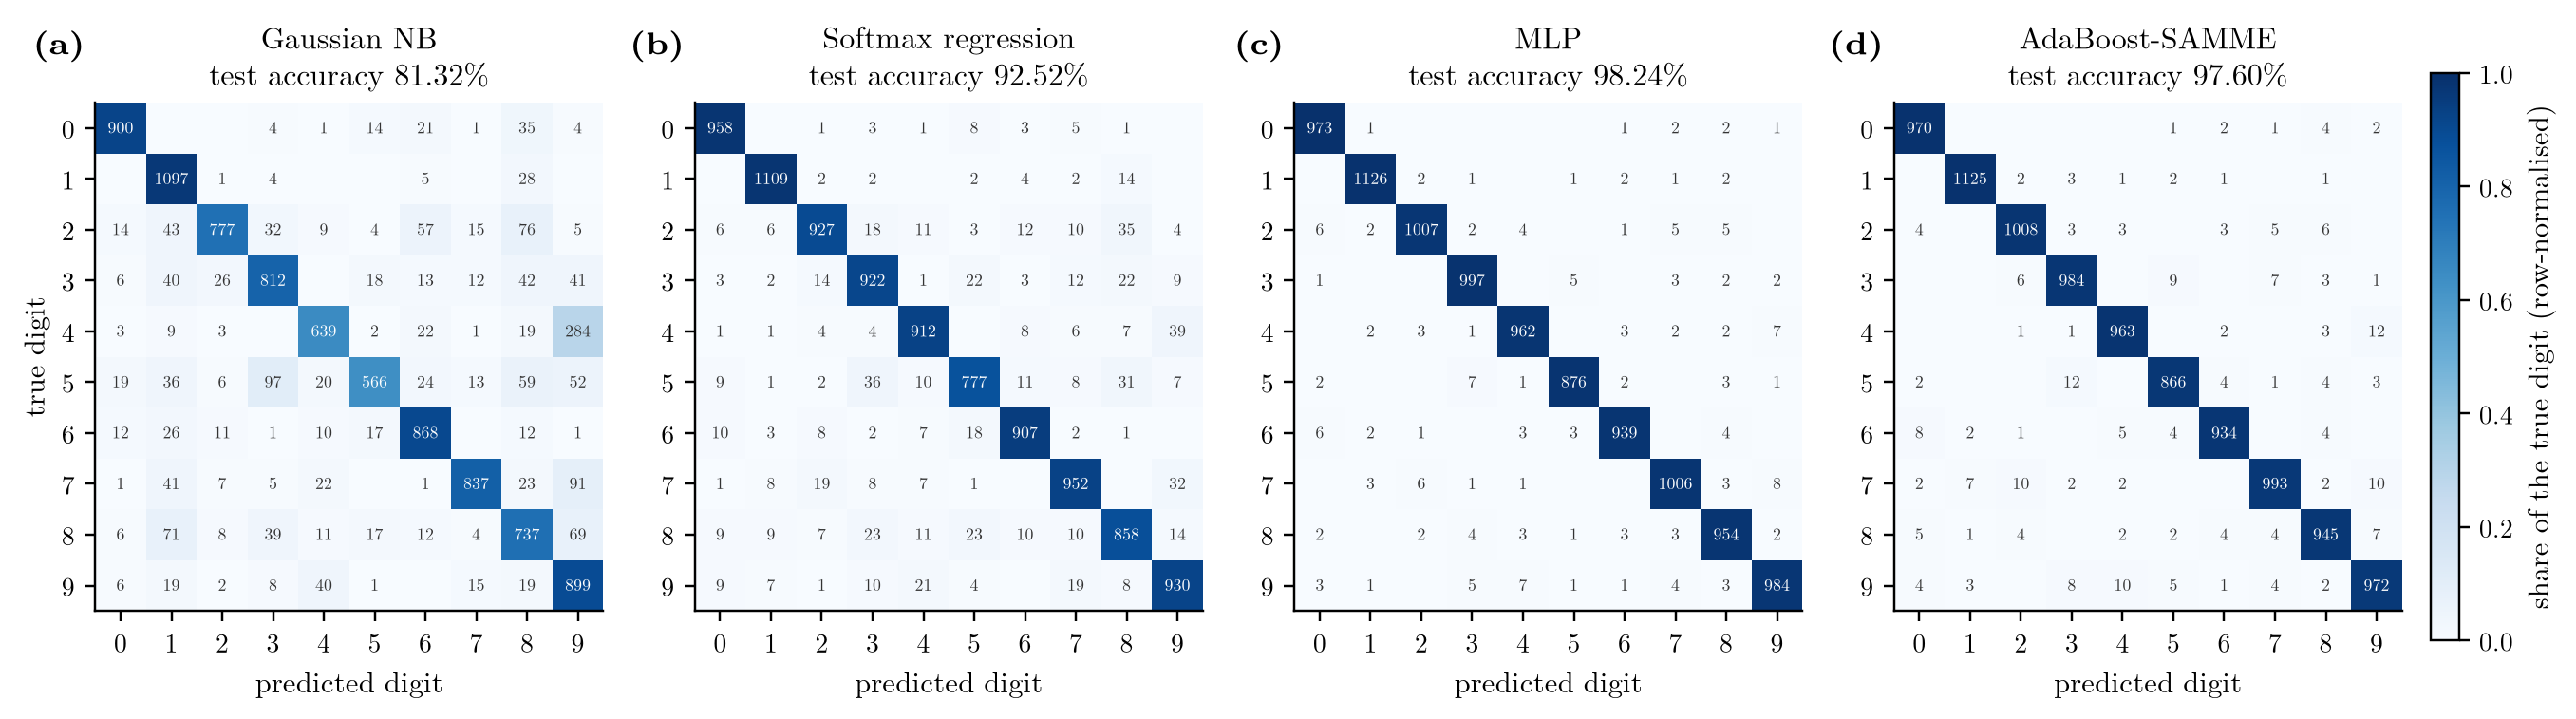

Gaussian NB [{'true': 4, 'pred': 9, 'count': 284}, {'true': 5, 'pred': 3, 'count': 97}, {'true': 7, 'pred': 9, 'count': 91}, {'true': 2, 'pred': 8, 'count': 76}, {'true': 8, 'pred': 1, 'count': 71}]
Softmax regression [{'true': 4, 'pred': 9, 'count': 39}, {'true': 5, 'pred': 3, 'count': 36}, {'true': 2, 'pred': 8, 'count': 35}, {'true': 7, 'pred': 9, 'count': 32}, {'true': 5, 'pred': 8, 'count': 31}]
MLP [{'true': 7, 'pred': 9, 'count': 8}, {'true': 9, 'pred': 4, 'count': 7}, {'true': 5, 'pred': 3, 'count': 7}, {'true': 4, 'pred': 9, 'count': 7}, {'true': 2, 'pred': 0, 'count': 6}]
AdaBoost-SAMME [{'true': 5, 'pred': 3, 'count': 12}, {'true': 4, 'pred': 9, 'count': 12}, {'true': 7, 'pred': 9, 'count': 10}, {'true': 7, 'pred': 2, 'count': 10}, {'true': 9, 'pred': 4, 'count': 10}]


In [6]:
display(Image(str(ROOT / "results" / "figures" / "confusion_all.png")))
for m in ORDER:
    print(TITLE[m], top_confusions(data[m]["final"]["splits"]["test"]["confusion_matrix"], 5))

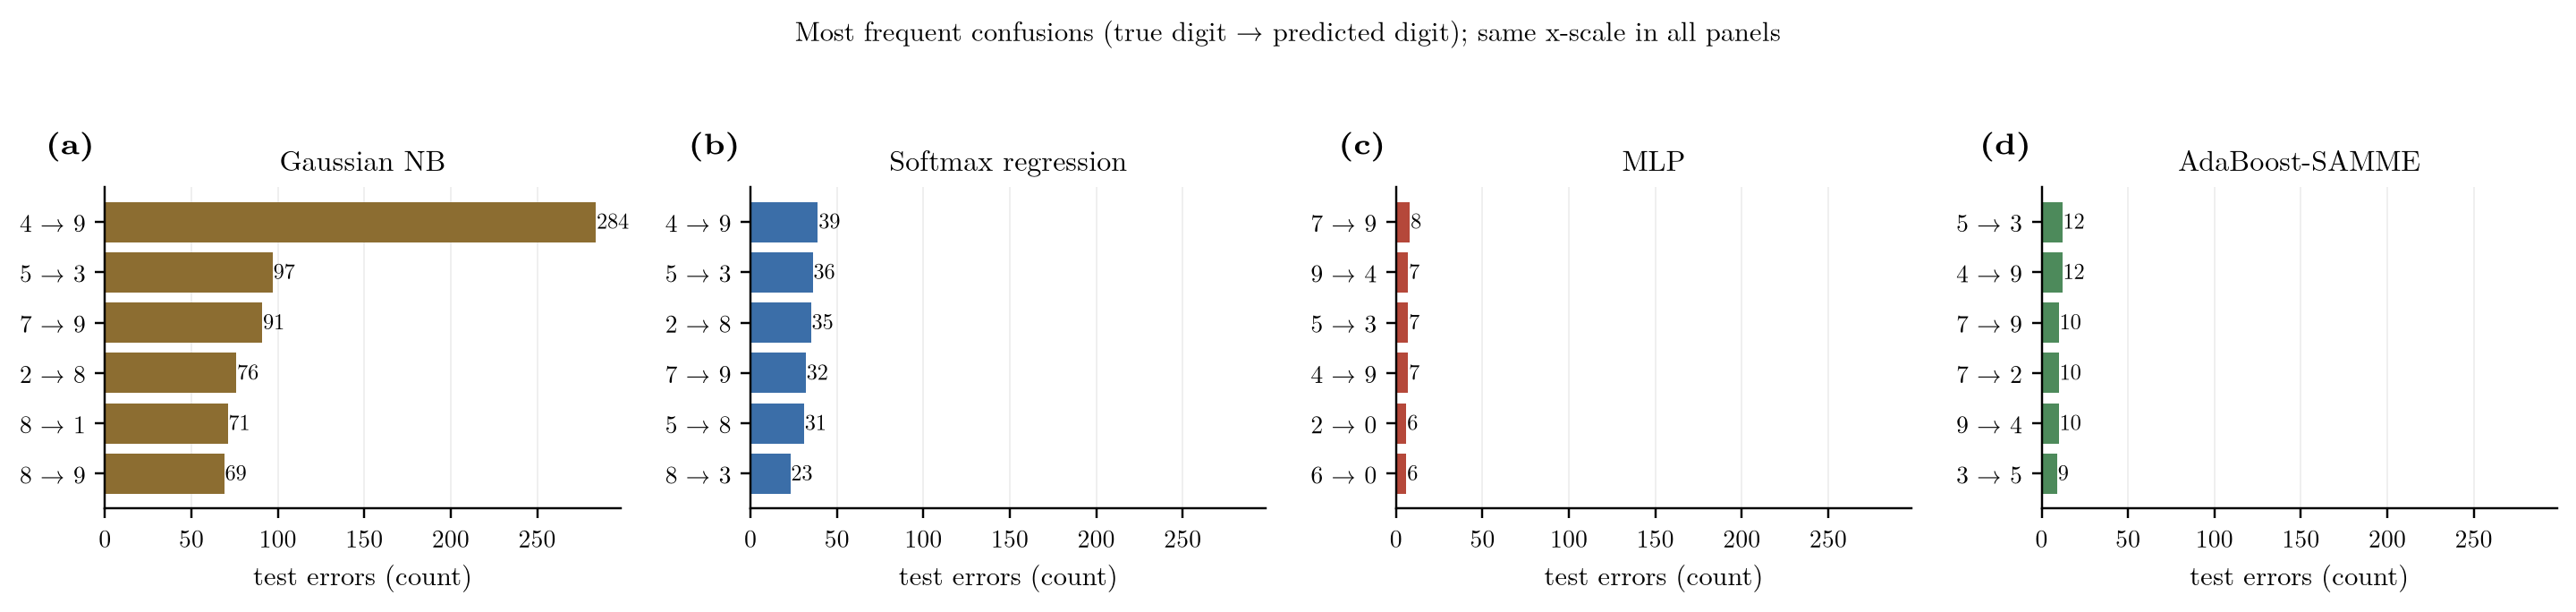

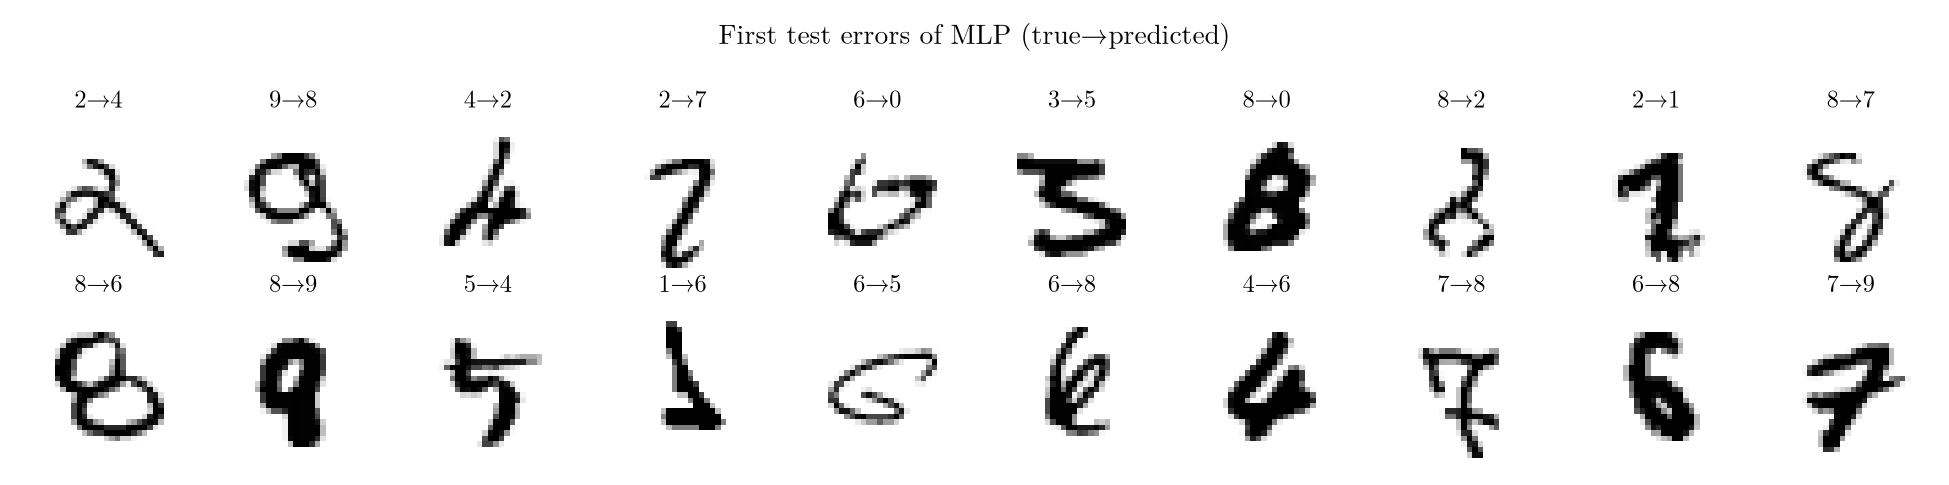

In [7]:
display(Image(str(ROOT / "results" / "figures" / "top_confusions.png"))); display(Image(str(ROOT / "results" / "figures" / "errors.png")))